In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt 

In [3]:
all_tables_2015 = pd.read_html("https://onscouting.org/2016/03/09/2015-merit-badge-rankings/", header=0)


In [4]:
len(all_tables_2015)

2

In [5]:
for i, t in enumerate(all_tables_2015):
    print(i, list(t.columns))
    #figure out if there is anythign i dont want 

0 ['Rank', 'Merit Badge', '2015']
1 ['Merit Badge', '2009', '2010', '2011', '2012', '2013', '2014', '2015']


In [6]:
scouts_2009_to_2015 = all_tables_2015[1]
scouts_2009_to_2015.shape
#i want merit badge so i put 1


(138, 8)

In [7]:
scouts_2009_to_2015

,Merit Badge,2009,2010,2011,2012,2013,2014,2015
0,American Business,685,667,707,679,805,650,587
1,American Cultures,2710,2353,2965,2883,2649,2174,2233
2,American Heritage,5625,5853,6645,6626,6195,5333,5599
3,American Labor,822,739,1168,811,1090,992,1106
4,Animal Science,3444,3591,3759,4503,4174,4042,4414
...,...,...,...,...,...,...,...,...
133,Welding,0,0,0,4022,10919,11061,11019
134,Whitewater,3993,3372,4322,4149,3252,3565,2888
135,Wilderness Survival,44632,41627,46757,46829,43158,40395,37581
136,Wood Carving,48489,45121,45645,44927,41120,38749,26890


In [8]:
all_tables_2020 = pd.read_html("https://onscouting.org/2021/02/24/2020-merit-badge-rankings-a-list-rewritten-by-the-pandemic/", header=0)


In [9]:
len(all_tables_2020)

9

In [10]:
for i, t in enumerate(all_tables_2020):
    print(i, list(t.columns))
    #figure out if there is anythign i dont want 

0 ['Rank', 'Merit Badge', '2020 earned', '2019 rank']
1 ['Rank', 'Merit Badge', '2020 earned']
2 ['Rank', 'Merit Badge', '2020 earned', '2019 rank']
3 ['Merit Badge', '2019', '2020', 'Percent change']
4 ['Merit Badge', '2019', '2020', 'Percent Change']
5 ['Rank', 'Merit Badge', 'Earned']
6 ['Merit Badge', '2016', '2017', '2018', '2019', '2020']
7 ['Rank', 'Merit Badge', 'Lifetime']
8 ['Merit Badge', '2019', '2020', 'Percent change']


In [11]:
#i want all years 



In [12]:
scouts_2016_to_2020 = all_tables_2020[6]
scouts_2016_to_2020.shape

(139, 6)

In [13]:
scouts_2016_to_2020

,Merit Badge,2016,2017,2018,2019,2020
0,American Business,627,613,551,1468,4967
1,American Cultures,2218,2298,2519,3089,2906
2,American Heritage,4952,5496,5530,5454,6700
3,American Labor,812,901,1109,1298,1892
4,Animal Science,3852,3848,3769,4155,2778
...,...,...,...,...,...,...
134,Welding,10737,10656,11981,11129,4709
135,Whitewater,3476,2832,3199,2890,1508
136,Wilderness Survival,35221,30814,29392,25863,11604
137,Wood Carving,34938,32943,31910,28599,9430


In [14]:
#i want to merge 

In [15]:

# how="outer" keeps every badge from both tables even ones that are only in one table. why do i care so i can see if anythgin doesnt match 
scouts_2009_to_2020 = pd.merge(scouts_2009_to_2015, scouts_2016_to_2020, on="Merit Badge", how="outer")

In [16]:
# check  size 
scouts_2009_to_2020.shape

(157, 13)

In [17]:
#no bueno shoudlnt be 157 somethign doesn tmatch up because first table had 138 next had 139 so one new bagde and now its like 18 new badges? cap 

In [18]:
scouts_2009_to_2020[scouts_2009_to_2020.isna().any(axis=1)]["Merit Badge"]

18                           Camping
19                          Camping*
24      Citizenship in the Community
25     Citizenship in the Community*
26         Citizenship in the Nation
27        Citizenship in the Nation*
28          Citizenship in the World
29         Citizenship in the World*
33                     Communication
34                    Communication*
37                           Cooking
38                          Cooking*
40                           Cycling
41                         Cycling**
49            Emergency Preparedness
50         Emergency Preparedness***
54             Environmental Science
55         Environmental Science****
56                       Exploration
57                       Family Life
58                      Family Life*
62                         First Aid
63                        First Aid*
75                            Hiking
76                          Hiking**
87                        Lifesaving
88                     Lifesaving***
1

In [19]:
#gotcha **** and coma 
scouts_2009_to_2015["Merit Badge"] = scouts_2009_to_2015["Merit Badge"].str.replace("*", "").str.strip()

In [20]:
# clean the badge names in both tables remove * remove space 
for table in [scouts_2009_to_2015, scouts_2016_to_2020]:
    table["Merit Badge"] = table["Merit Badge"].str.replace("*", "").str.replace(", and", " and").str.strip()

In [21]:
scouts_2009_to_2020 = pd.merge(scouts_2009_to_2015, scouts_2016_to_2020, on="Merit Badge", how="outer")


In [22]:
scouts_2009_to_2020.shape

(139, 13)

In [23]:
scouts_2009_to_2020

,Merit Badge,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,American Business,685.0,667.0,707.0,679.0,805.0,650.0,587.0,627,613,551,1468,4967
1,American Cultures,2710.0,2353.0,2965.0,2883.0,2649.0,2174.0,2233.0,2218,2298,2519,3089,2906
2,American Heritage,5625.0,5853.0,6645.0,6626.0,6195.0,5333.0,5599.0,4952,5496,5530,5454,6700
3,American Labor,822.0,739.0,1168.0,811.0,1090.0,992.0,1106.0,812,901,1109,1298,1892
4,Animal Science,3444.0,3591.0,3759.0,4503.0,4174.0,4042.0,4414.0,3852,3848,3769,4155,2778
...,...,...,...,...,...,...,...,...,...,...,...,...,...
134,Welding,0.0,0.0,0.0,4022.0,10919.0,11061.0,11019.0,10737,10656,11981,11129,4709
135,Whitewater,3993.0,3372.0,4322.0,4149.0,3252.0,3565.0,2888.0,3476,2832,3199,2890,1508
136,Wilderness Survival,44632.0,41627.0,46757.0,46829.0,43158.0,40395.0,37581.0,35221,30814,29392,25863,11604
137,Wood Carving,48489.0,45121.0,45645.0,44927.0,41120.0,38749.0,26890.0,34938,32943,31910,28599,9430


In [24]:

totals_per_year = scouts_2009_to_2020.drop(columns="Merit Badge").sum()

In [25]:

totals_per_year

2009    2096676.0
2010    2056867.0
2011    2164366.0
2012    2175878.0
2013    2110848.0
2014    2077550.0
2015    2001842.0
2016    1919912.0
2017    1813834.0
2018    1822136.0
2019    1742398.0
2020    1105871.0
dtype: float64

In [26]:
#making a chart? this the size 
plt.figure(figsize=(10, 5))

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

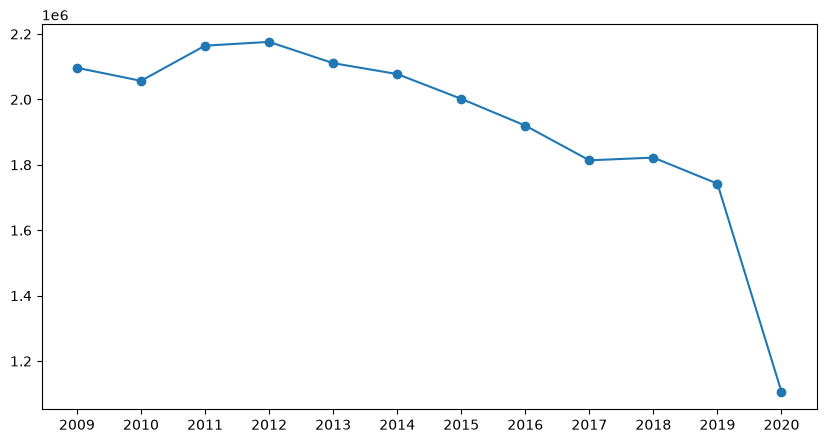

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(totals_per_year.index, totals_per_year.values, marker="o")


Text(0.5, 1.0, 'Total merit badges earned per year, 2009-2020')

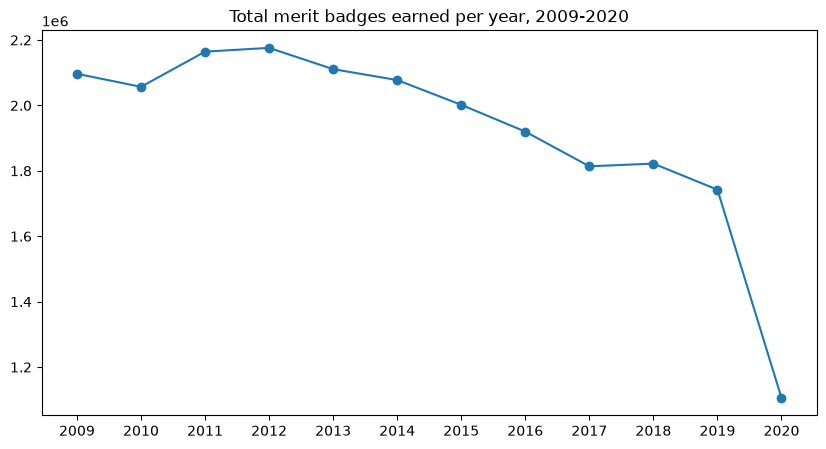

In [28]:
#label up 
plt.figure(figsize=(10, 5))
plt.plot(totals_per_year.index, totals_per_year.values, marker="o")
plt.title("Total merit badges earned per year, 2009-2020")

Text(0, 0.5, 'Badges earned')

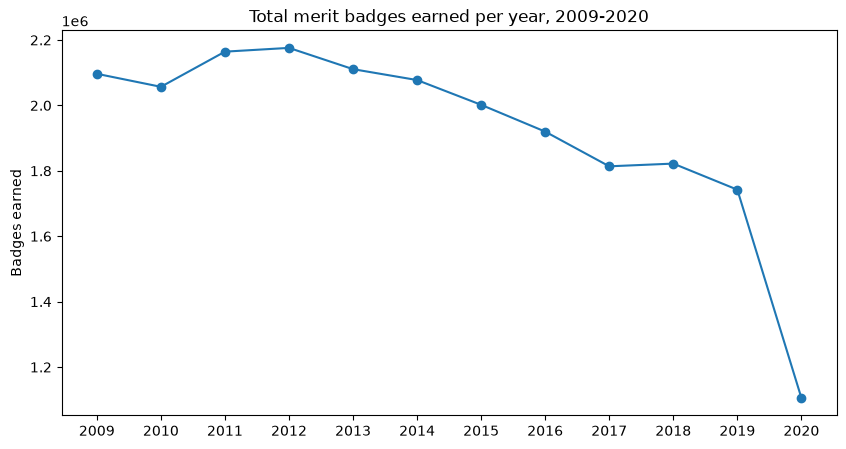

In [29]:
#label left 
plt.figure(figsize=(10, 5))
plt.plot(totals_per_year.index, totals_per_year.values, marker="o")
plt.title("Total merit badges earned per year, 2009-2020")
plt.ylabel("Badges earned")

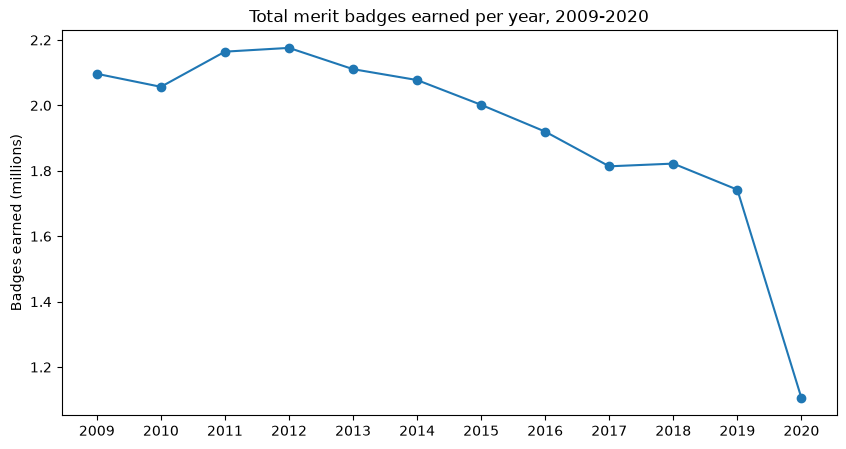

In [30]:
#remove the 1e6 im too dyslexic to count 
plt.figure(figsize=(10, 5))
plt.plot(totals_per_year.index, totals_per_year.values / 1000000, marker="o")
plt.title("Total merit badges earned per year, 2009-2020")
plt.ylabel("Badges earned (millions)")
plt.show()

In [31]:
# focuses on the merit badge  name 
by_badge = scouts_2009_to_2020.set_index("Merit Badge")

# top badge name for each year
max_badge = by_badge.idxmax()

# how many of the top badge were earned each year
max_value = by_badge.max()

In [32]:
# see the top badge and numb for each yrs printed
print(max_badge)
print(max_value)

2009      First Aid
2010      First Aid
2011      First Aid
2012      First Aid
2013      First Aid
2014        Cooking
2015      First Aid
2016      First Aid
2017      First Aid
2018      First Aid
2019      First Aid
2020    Family Life
dtype: str
2009    91334.0
2010    89694.0
2011    94268.0
2012    92312.0
2013    87477.0
2014    99908.0
2015    80716.0
2016    75256.0
2017    69563.0
2018    69565.0
2019    62352.0
2020    48408.0
dtype: float64


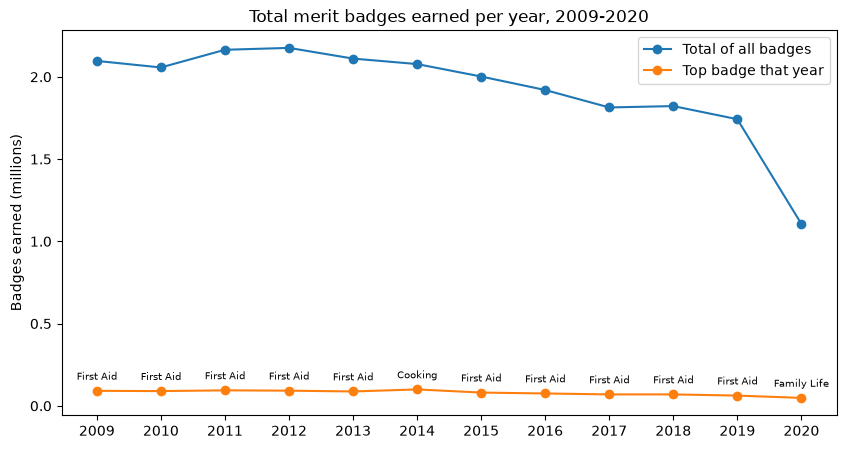

In [33]:
#this looks better
#remove the 1e6 
plt.figure(figsize=(10, 5))
plt.plot(totals_per_year.index, totals_per_year.values / 1000000, marker="o")
plt.title("Total merit badges earned per year, 2009-2020")
plt.ylabel("Badges earned (millions)")

#plots the points of the value
plt.plot(max_value.index, max_value.values / 1000000, marker="o")

#labels
for year in max_value.index:
    plt.annotate(max_badge[year], xy=(year, max_value[year] / 1000000), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=7)



plt.legend(["Total of all badges", "Top badge that year"])

plt.show()

In [34]:
# empty box to collect each year's top 3
top_3 = {}

# go through each year and grab the 3 biggest badges and stores it in top 3 
for year in by_badge.columns:
    top_3[year] = list(by_badge[year].nlargest(3).index)

# turn it into a table one row per year top 3 
top_3_table = pd.DataFrame(top_3, index=["1st", "2nd", "3rd"]).T
top_3_table

,1st,2nd,3rd
2009,First Aid,Environmental Science,Swimming
2010,First Aid,Swimming,Environmental Science
2011,First Aid,Swimming,Environmental Science
2012,First Aid,Swimming,Environmental Science
2013,First Aid,Swimming,Environmental Science
2014,Cooking,First Aid,Swimming
2015,First Aid,Swimming,Cooking
2016,First Aid,Swimming,Environmental Science
2017,First Aid,Swimming,Citizenship in the World
2018,First Aid,Swimming,Citizenship in the World


In [35]:
#2020 comepleley makes sense 

In [36]:
#kids care about knowing safety and stuff maybe we should do a badge episode about first aid 

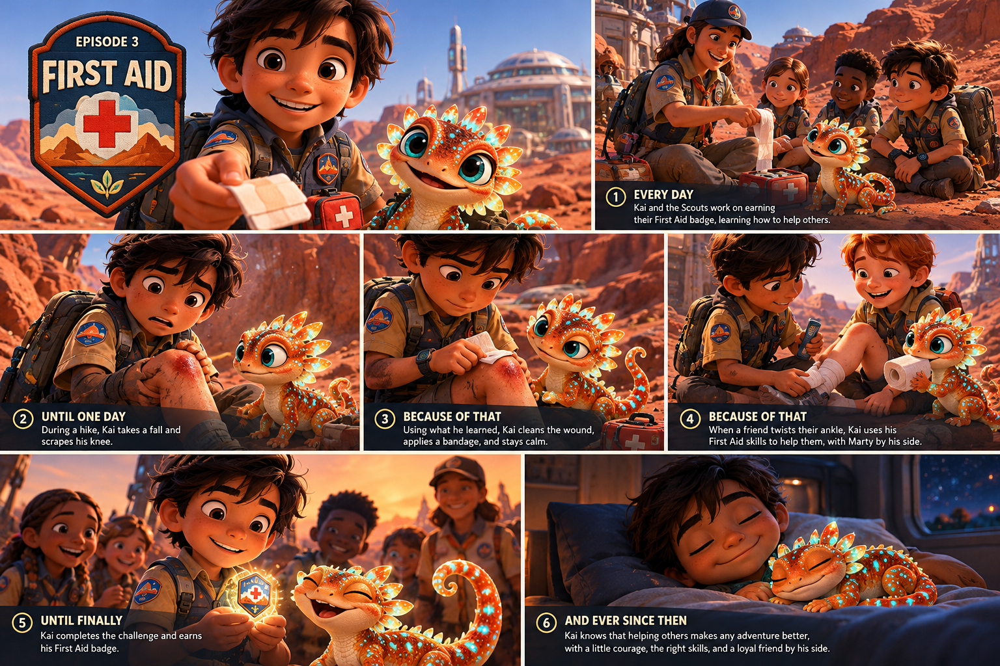

In [37]:
from IPython.display import Image
Image("Cookies/Mars Scouts_ First Aid Adventure.png", width=600)

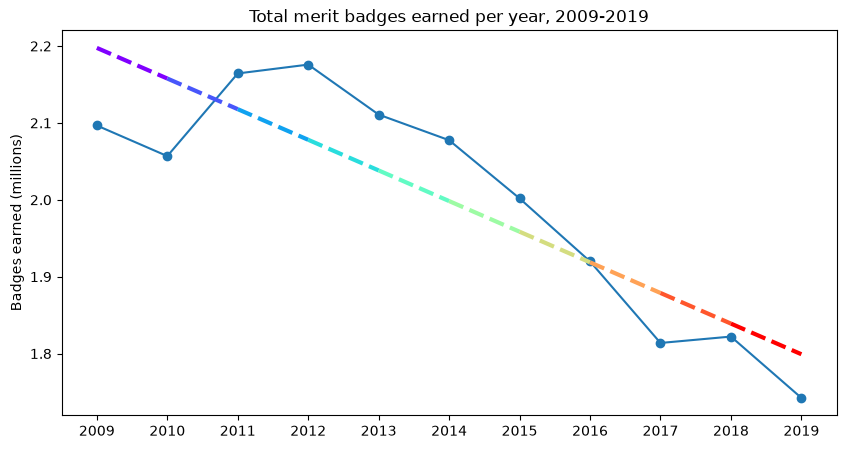

In [38]:
#line of best fit total badge trend
import numpy as np

# leave out 2020
totals = totals_per_year.drop("2020")

#remove the 1e6
plt.figure(figsize=(10, 5))
plt.plot(totals.index, totals.values / 1000000, marker="o")

# work out the line of best fit's height at each year
best_fit = np.poly1d(np.polyfit(range(len(totals)), totals.values / 1000000, 1))(range(len(totals)))

#rainbow color line
for i in range(len(totals) - 1):
    plt.plot(totals.index[i:i+2], best_fit[i:i+2], "--", linewidth=3, color=plt.cm.rainbow(i / (len(totals) - 2)))

plt.title("Total merit badges earned per year, 2009-2019")
plt.ylabel("Badges earned (millions)")
plt.show()

In [39]:
#I then notice a small stabilization in 2018 and wondered what that meant what happened then they where going down every year minut that from 2012


In [40]:


#I then found out in 2018 they allowed woman to enroll which they came out as diversity but in reality seeing this and what you will see later it might have been a financial decision,
#they where even sued by girl scouts for doing this

#this still didnt save them from their decline 

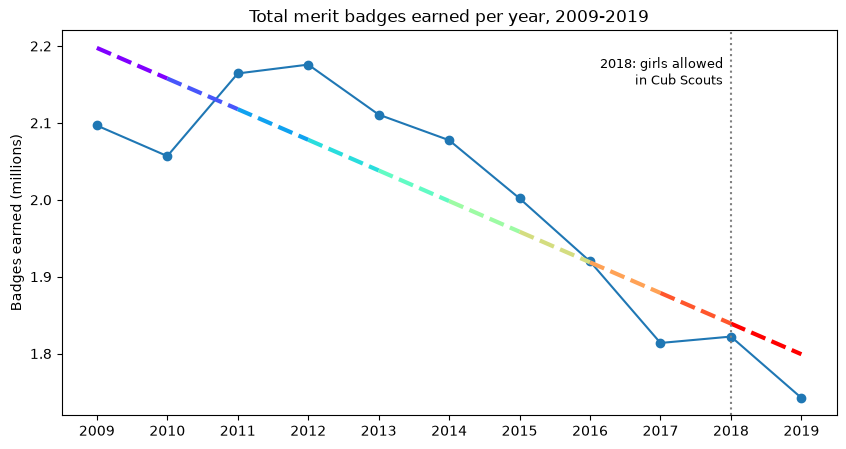

In [41]:
#showing where this happened 
import numpy as np

# leave out 2020
totals = totals_per_year.drop("2020")

#remove the 1e6
plt.figure(figsize=(10, 5))
plt.plot(totals.index, totals.values / 1000000, marker="o")

# work out the line of best fit's height at each year
best_fit = np.poly1d(np.polyfit(range(len(totals)), totals.values / 1000000, 1))(range(len(totals)))

# rainbow colour line
for i in range(len(totals) - 1):
    plt.plot(totals.index[i:i+2], best_fit[i:i+2], "--", linewidth=3, color=plt.cm.rainbow(i / (len(totals) - 2)))

plt.title("Total merit badges earned per year, 2009-2019")
plt.ylabel("Badges earned (millions)")
# dotted line at 2018
plt.axvline("2018", color="gray", linestyle=":")

plt.text("2018", 2.15, "2018: girls allowed  \nin Cub Scouts  ", fontsize=9, ha="right")
plt.show()

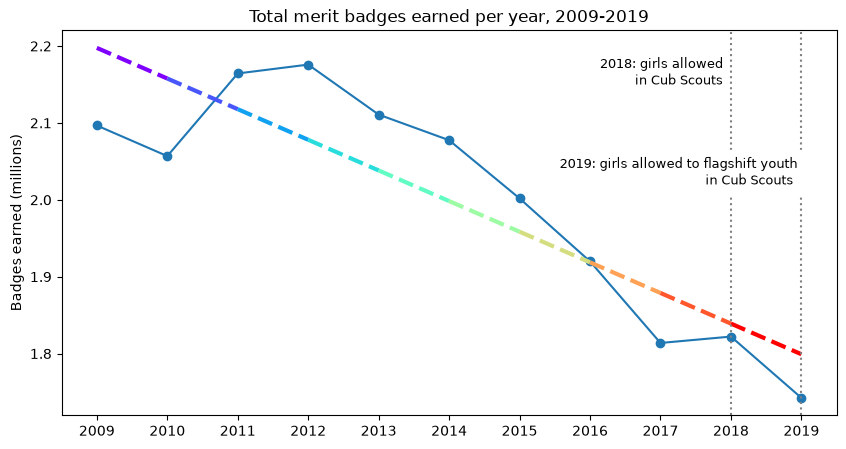

In [42]:
import numpy as np

# leave out 2020
totals = totals_per_year.drop("2020")

#remove the 1e6
plt.figure(figsize=(10, 5))
plt.plot(totals.index, totals.values / 1000000, marker="o")

# work out the line of best fit's height at each year
best_fit = np.poly1d(np.polyfit(range(len(totals)), totals.values / 1000000, 1))(range(len(totals)))

# rainbow colour line
for i in range(len(totals) - 1):
    plt.plot(totals.index[i:i+2], best_fit[i:i+2], "--", linewidth=3, color=plt.cm.rainbow(i / (len(totals) - 2)))

plt.title("Total merit badges earned per year, 2009-2019")
plt.ylabel("Badges earned (millions)")
# dotted line at 2018
plt.axvline("2018", color="gray", linestyle=":")
plt.axvline("2019", color="gray", linestyle=":")

plt.text("2018", 2.15, "2018: girls allowed  \nin Cub Scouts  ", fontsize=9, ha="right")
plt.text("2019", 2.02, "2019: girls allowed to flagshift youth \nin Cub Scouts  ", fontsize=9, ha="right", backgroundcolor="white")
plt.show()

In [43]:
#here im thinking that maybe the bumb in badge amount increase came up because they brought in girls but then
#i found out they only allowed girls to then be able to adquire the flagshift badges in 2019 so this the case its just 

In [44]:

#i remebbered floating average wanted to see it 

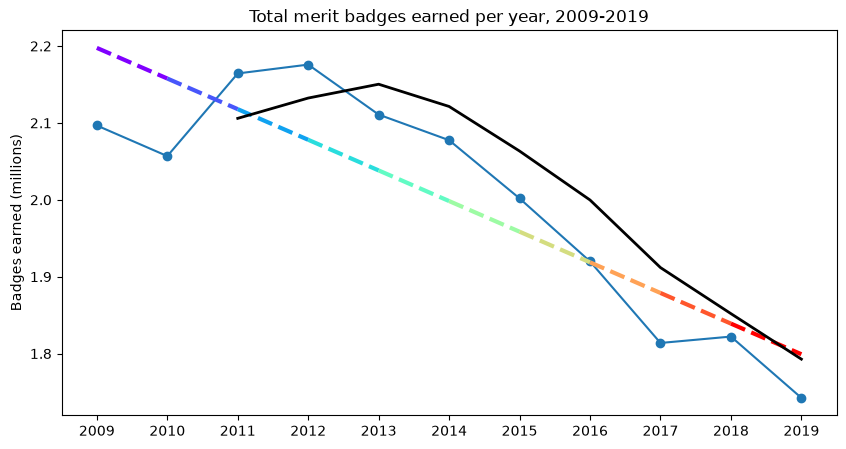

In [45]:
import numpy as np

# leave out 2020
totals = totals_per_year.drop("2020")

#remove the 1e6
plt.figure(figsize=(10, 5))
plt.plot(totals.index, totals.values / 1000000, marker="o", label="Total badges earned")

# work out the line of best fit's height at each year
best_fit = np.poly1d(np.polyfit(range(len(totals)), totals.values / 1000000, 1))(range(len(totals)))

# rainbow colour line
for i in range(len(totals) - 1):
    if i == 0:
        plt.plot(totals.index[i:i+2], best_fit[i:i+2], "--", linewidth=3, color=plt.cm.rainbow(i / (len(totals) - 2)), label="Line of best fit")
    else:
        plt.plot(totals.index[i:i+2], best_fit[i:i+2], "--", linewidth=3, color=plt.cm.rainbow(i / (len(totals) - 2)))

# 3-year moving average
plt.plot(totals.index, totals.rolling(3).mean() / 1000000, color="black", linewidth=2, label="3-year moving average")

plt.title("Total merit badges earned per year, 2009-2019")
plt.ylabel("Badges earned (millions)")
# dotted line at 2018


plt.show()

In [46]:
#at this point im like ok lets focus its been going down since 2012 or 2013 with flaoting average  why? i know covid was nail in the coufin, what happened with before and what happened after?

In [47]:
#i need to get past 2020 and funny enough i knew when i started this search that for some reason they stopped publicating amount of badges total past 2020 and only reported rankings of badges
#so not only we want to merge but we need to first convert our current datat into ranking to be able to merge it with the ranking of 2020 and beyond 


In [48]:
#back to bizzzz lets merge

# put badge names on the rows
by_badge = scouts_2009_to_2020.set_index("Merit Badge")

#first turns 0s (meaning they didnt exsit into nan then ranks. 
ranks_2009_to_2020 = by_badge.replace(0, float("nan")).rank(ascending=False, method="min")

# sort the badges A to Z
ranks_2009_to_2020 = ranks_2009_to_2020.sort_index()
ranks_2009_to_2020.head(10)
ranks_2009_to_2020.shape

(139, 12)

In [49]:
#that matches what we used to have so we good 139, 12 goes to 13 because merit badge changed position it is what it is 
scouts_2009_to_2020.shape

(139, 13)

In [50]:
#lets do some extracting 
# each year's article
urls = {
    "2021": "https://onscouting.org/2022/04/26/2021-merit-badge-rankings-return-of-summer-camps-shuffles-the-list-again/",
    "2022": "https://onscouting.org/2023/02/28/2022-merit-badge-rankings-a-new-chart-topper-emerges/",
    "2023": "https://onscouting.org/2024/02/13/2023-merit-badge-rankings-a-look-into-scouts-current-interests-and-achievements/",
    "2024": "https://onscouting.org/2025/03/06/the-2024-merit-badge-rankings-take-a-swing-at-guessing-what-made-the-largest-gains-this-year/",
    "2025": "https://onscouting.org/2026/03/18/first-aid-is-first-again-2025-merit-badge-rankings-are-here/",
}

# list every table on each article: its number, its size (rows, columns), and its column names
for year, url in urls.items():
    print("----", year, "----")
    for i, t in enumerate(pd.read_html(url, header=0)):
        print(i, t.shape, list(t.columns))

---- 2021 ----
0 (10, 2) ['2021 Rank', 'Merit Badge']
1 (10, 3) ['Alternative Rank', 'Merit Badge', 'Actual 2021 Rank']
2 (10, 2) ['2021 Rank', 'Merit Badge']
3 (10, 4) ['2021 Rank', 'Merit Badge', '2020 Rank', 'Difference']
4 (10, 4) ['2021 Rank', 'Merit Badge', '2020 Rank', 'Difference']
5 (137, 4) ['2021 Rank', 'Merit Badge', '2020 Rank', 'Difference']
---- 2022 ----
0 (10, 2) ['2022 Rank', 'Merit Badge']
1 (10, 2) ['2022 Rank', 'Merit Badge']
2 (10, 2) ['2022 Rank', 'Merit Badge']
3 (10, 4) ['2022 Rank', 'Merit Badge', '2021 Rank', 'Difference']
4 (138, 4) ['2022 Rank', 'Merit Badge', '2021 Rank', 'Difference']
---- 2023 ----
0 (10, 2) ['2023 Rank', 'Merit Badge']
1 (10, 2) ['2023 Rank', 'Merit Badge']
2 (10, 2) ['2023 Rank', 'Merit Badge']
3 (10, 4) ['2023 Rank', 'Merit Badge', '2022 Rank', 'Difference']
4 (138, 4) ['2023 Rank', 'Merit Badge', '2022 Rank', 'Rank Difference']
---- 2024 ----
0 (10, 2) ['2024 Rank', 'Merit Badge']
1 (10, 2) ['2024 Rank', 'Merit Badge']
2 (10, 2) ['20

In [51]:
#(numbers i coudl see from above) which one i wanted to keep all the same 
pages = {
    "2021": ("https://onscouting.org/2022/04/26/2021-merit-badge-rankings-return-of-summer-camps-shuffles-the-list-again/", 5, "2021 Rank"),
    "2022": ("https://onscouting.org/2023/02/28/2022-merit-badge-rankings-a-new-chart-topper-emerges/", 4, "2022 Rank"),
    "2023": ("https://onscouting.org/2024/02/13/2023-merit-badge-rankings-a-look-into-scouts-current-interests-and-achievements/", 4, "2023 Rank"),
    "2024": ("https://onscouting.org/2025/03/06/the-2024-merit-badge-rankings-take-a-swing-at-guessing-what-made-the-largest-gains-this-year/", 4, "2024"),
    "2025": ("https://onscouting.org/2026/03/18/first-aid-is-first-again-2025-merit-badge-rankings-are-here/", 0, "2025 Rank"),
}

ranks_2021_to_2025 = None

for year, (url, table_number, rank_column) in pages.items():
    # grab the right table from that years article
    table = pd.read_html(url, header=0)[table_number]

    # keep just the badge name and the rank and call the rank column by its year
    table = table[["Merit Badge", rank_column]].rename(columns={rank_column: year})

   

    # first year starts the table, every other year gets merged on
    if ranks_2021_to_2025 is None:
        ranks_2021_to_2025 = table
    else:
        ranks_2021_to_2025 = pd.merge(ranks_2021_to_2025, table, on="Merit Badge", how="outer")

# badge names on the rows, like your 2009-2020 table
ranks_2021_to_2025 = ranks_2021_to_2025.set_index("Merit Badge")
ranks_2021_to_2025.shape

(146, 5)

In [52]:
#so i added this line and then removed to see if it changed 

    # clean the names: remove stars, the extra comma, and spaces
   # table["Merit Badge"] = table["Merit Badge"].str.replace("*", "").str.replace(", and", " and").str.strip()

#to see if anythgin changed somethign did change in shape so i know i had to keep it 

In [53]:
#(numbers i coudl see from above) 
pages = {
    "2021": ("https://onscouting.org/2022/04/26/2021-merit-badge-rankings-return-of-summer-camps-shuffles-the-list-again/", 5, "2021 Rank"),
    "2022": ("https://onscouting.org/2023/02/28/2022-merit-badge-rankings-a-new-chart-topper-emerges/", 4, "2022 Rank"),
    "2023": ("https://onscouting.org/2024/02/13/2023-merit-badge-rankings-a-look-into-scouts-current-interests-and-achievements/", 4, "2023 Rank"),
    "2024": ("https://onscouting.org/2025/03/06/the-2024-merit-badge-rankings-take-a-swing-at-guessing-what-made-the-largest-gains-this-year/", 4, "2024"),
    "2025": ("https://onscouting.org/2026/03/18/first-aid-is-first-again-2025-merit-badge-rankings-are-here/", 0, "2025 Rank"),
}

ranks_2021_to_2025 = None

for year, (url, table_number, rank_column) in pages.items():
    # grab the right table from that year's article
    table = pd.read_html(url, header=0)[table_number]

    # keep just the badge name and the rank, and call the rank column by its year
    table = table[["Merit Badge", rank_column]].rename(columns={rank_column: year})

    # clean the names: remove stars, the extra comma, and spaces
    table["Merit Badge"] = table["Merit Badge"].str.replace("*", "").str.replace(", and", " and").str.strip()

    # first year starts the table, every other year gets merged on
    if ranks_2021_to_2025 is None:
        ranks_2021_to_2025 = table
    else:
        ranks_2021_to_2025 = pd.merge(ranks_2021_to_2025, table, on="Merit Badge", how="outer")

# badge names on the rows like your 2009--2020 table
ranks_2021_to_2025 = ranks_2021_to_2025.set_index("Merit Badge")
ranks_2021_to_2025.shape

(144, 5)

In [54]:
#i see new badges bygoing from 139 to 144
#so at this point im reminded to merge and also that they only published rnaking not numbers, to me thats because the numbers where showing crazy drops in interest which looked bad 

In [55]:
# glue 2009-2020 and 2021-2025 together by badge name (the row labels)
ranks_2009_to_2025 = pd.merge(ranks_2009_to_2020, ranks_2021_to_2025, left_index=True, right_index=True, how="outer")
ranks_2009_to_2025.shape


(146, 17)

In [56]:
#146 lets me know i need to clean somethign 



In [57]:
#i think coudl it be somethign about the badges that didnt exist before 
# show every badge that has empty years
pd.set_option("display.max_rows", None)
ranks_2009_to_2025[ranks_2009_to_2025.isna().any(axis=1)]

,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
Merit Badge,,,,,,,,,,,,,,,,,
American Indian Culture (Indian Lore),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.0
Animation,NaN,NaN,NaN,NaN,NaN,NaN,133.0,87.0,83.0,69.0,66.0,78.0,59.0,60.0,59.0,61.0,54.0
Artificial Intelligence,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,134.0
Chess,NaN,NaN,82.0,21.0,24.0,24.0,21.0,22.0,21.0,21.0,20.0,15.0,21.0,21.0,16.0,19.0,19.0
Cinematography,75.0,75.0,67.0,66.0,67.0,97.0,131.0,133.0,138.0,139.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Citizenship in Society,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,4.0,6.0
Computers,44.0,44.0,46.0,47.0,42.0,45.0,127.0,138.0,139.0,138.0,138.0,NaN,NaN,NaN,NaN,NaN,NaN
Cybersecurity,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,135.0
Digital Technology,NaN,NaN,NaN,NaN,NaN,112.0,62.0,60.0,58.0,63.0,68.0,29.0,68.0,74.0,70.0,69.0,72.0


In [58]:
#i see scuba 
#i see medicine and healthcare 
#indian lore

#spelled diff so lets fix


In [59]:
# rename the new badge names back to the old ones so each pair has the same name
ranks_2009_to_2025 = ranks_2009_to_2025.rename(index={
    "SCUBA Diving": "Scuba Diving",
    "Medicine/Health Care Professions": "Medicine",
    "American Indian Culture (Indian Lore)": "Indian Lore"
})

# squish rows with the same name into one row fills each year from whichever row has a number
ranks_2009_to_2025 = ranks_2009_to_2025.groupby(level=0).first()
ranks_2009_to_2025.shape

(143, 17)

In [60]:
#now im curious which where top 3 and bottom 3 
# empty box to collect each year's top 3 and bottom 3
top_bottom = {}

for year in ranks_2009_to_2025.columns:
    # smallest rank numbers = top badges 1-3
    top = list(ranks_2009_to_2025[year].nsmallest(3).index)

    # biggest rank numbers = least earned badges
    bottom = list(ranks_2009_to_2025[year].nlargest(3).index)

    # put them together for this year
    top_bottom[year] = top + bottom

# turn it into a table one row per year
top_bottom_table = pd.DataFrame(top_bottom, index=["1st", "2nd", "3rd", "Last", "2nd last", "3rd last"]).T
top_bottom_table

,1st,2nd,3rd,Last,2nd last,3rd last
2009,First Aid,Environmental Science,Swimming,Scuba Diving,Fly Fishing,Bugling
2010,First Aid,Swimming,Environmental Science,Fly Fishing,Inventing,American Business
2011,First Aid,Swimming,Environmental Science,Bugling,American Business,Surveying
2012,First Aid,Swimming,Environmental Science,Bugling,American Business,Search and Rescue
2013,First Aid,Swimming,Environmental Science,Programming,Bugling,Sustainability
2014,Cooking,First Aid,Swimming,Bugling,American Business,Stamp Collecting
2015,First Aid,Swimming,Cooking,Bugling,American Business,Surveying
2016,First Aid,Swimming,Environmental Science,Computers,Bugling,American Business
2017,First Aid,Swimming,Citizenship in the World,Computers,Cinematography,Bugling
2018,First Aid,Swimming,Citizenship in the World,Cinematography,Computers,American Business


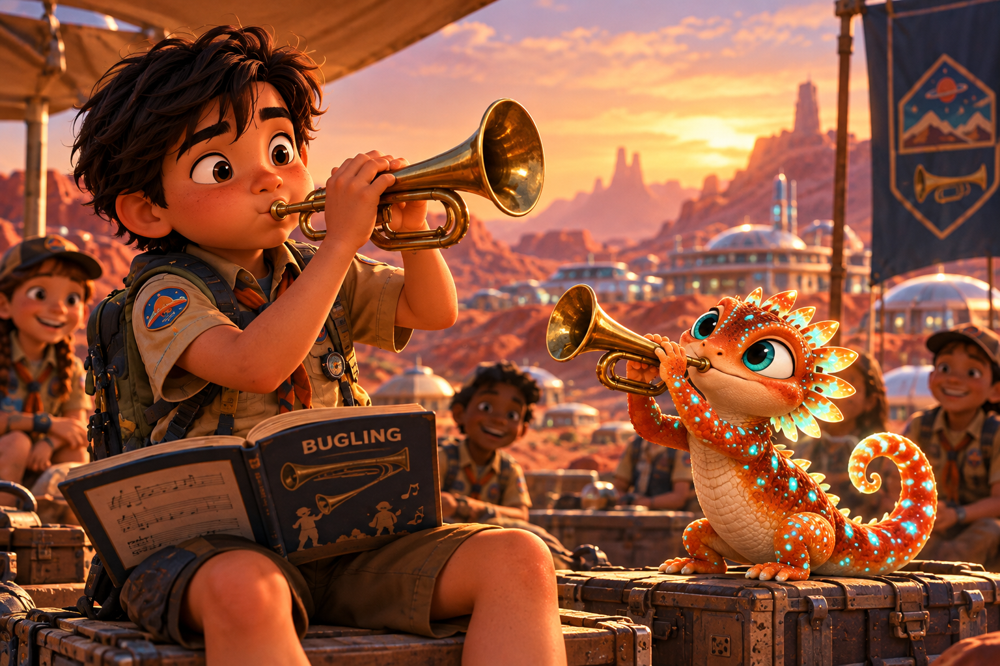

In [61]:
from IPython.display import Image
#Bugling is the merit badge for playing the bugle, a small brass horn like a trumpet but without any buttons or valves. You change notes only with your lips.
#stay away from a martian bugling episode unless its as a deep deep joke 
Image("Bugling at the Mars Scout Camp.png", width=600)

In [62]:

#most definily swiming is big 
#american bizzz really low these kids are real real kids enjoying life 
#17 year olds can even get this and its really really low 



In [63]:
# new badges per year 
first_year = ranks_2009_to_2025.notna().idxmax(axis=1)

# 2009 is where the data starts
new_badges = first_year[first_year != "2009"]
new_badges.sort_values()

Merit Badge
Scouting Heritage           2010
Inventing                   2010
Geocaching                  2010
Chess                       2011
Robotics                    2011
Kayaking                    2012
Search and Rescue           2012
Welding                     2012
Sustainability              2013
Programming                 2013
Game Design                 2013
Digital Technology          2014
Mining in Society           2014
Moviemaking                 2014
Signs, Signals and Codes    2015
Animation                   2015
Exploration                 2017
Citizenship in Society      2022
Multisport                  2025
Cybersecurity               2025
Artificial Intelligence     2025
dtype: str

In [64]:
#curiouse about performance of badges when brought in 
# for each new badge its first rank 1-4 years later best rank ever and rank in 2025
launch = {}

for badge, start in new_badges.items():
    # this badges ranks from its first year onward
    after = ranks_2009_to_2025.loc[badge, start:].dropna()

    launch[badge] = {
        "debut year": start,
        "debut rank": after.iloc[0],
        "1 yr later": after.iloc[1] if len(after) > 1 else None,
        "2 yrs later": after.iloc[2] if len(after) > 2 else None,
        "3 yrs later": after.iloc[3] if len(after) > 3 else None,
        "4 yrs later": after.iloc[4] if len(after) > 4 else None,
        "best rank": after.min(),
        "2025 rank": ranks_2009_to_2025.loc[badge, "2025"],
    }

launch_table = pd.DataFrame(launch).T.sort_values("debut year")
launch_table

,debut year,debut rank,1 yr later,2 yrs later,3 yrs later,4 yrs later,best rank,2025 rank
Scouting Heritage,2010,94.0,79.0,87.0,85.0,81.0,47.0,77.0
Inventing,2010,124.0,115.0,115.0,113.0,115.0,103.0,119.0
Geocaching,2010,89.0,35.0,38.0,36.0,37.0,35.0,53.0
Chess,2011,82.0,21.0,24.0,24.0,21.0,15.0,19.0
Robotics,2011,87.0,50.0,46.0,44.0,42.0,34.0,45.0
Kayaking,2012,32.0,20.0,20.0,19.0,20.0,14.0,21.0
Search and Rescue,2012,128.0,58.0,49.0,50.0,54.0,43.0,43.0
Welding,2012,101.0,55.0,54.0,51.0,53.0,36.0,39.0
Sustainability,2013,131.0,84.0,76.0,72.0,66.0,25.0,25.0
Programming,2013,133.0,113.0,102.0,96.0,95.0,77.0,96.0


In [65]:
#citizenship in society when world is doing somethign kids really go into it 
#"The Citizenship in Society merit badge is a Scouting America program focused on diversity, equity, inclusion (DEI), and ethical leadership"

In [66]:
#want to find out if there is any freshishly outperforming badges when they debut 
#how many places each badge climbed from its debut year to 1 year later (positive = moved up)
launch_table["jump"] = pd.to_numeric(launch_table["debut rank"] - launch_table["1 yr later"])

# the average jump, and the typical spread (standard deviation)
print("average jump:", round(launch_table["jump"].mean(), 1))
print("standard deviation:", round(launch_table["jump"].std(), 1))

average jump: 35.0
standard deviation: 21.0


In [67]:
# z-scorehow many standard deviations each jump is from the average
launch_table["z"] = (launch_table["jump"] - launch_table["jump"].mean()) / launch_table["jump"].std()

In [68]:
# biggest climb first in order positive 
launch_table.sort_values("jump", ascending=False)[["debut year", "debut rank", "1 yr later", "jump", "z"]]

,debut year,debut rank,1 yr later,jump,z
Search and Rescue,2012,128.0,58.0,70.0,1.667445
Game Design,2013,114.0,51.0,63.0,1.333956
Chess,2011,82.0,21.0,61.0,1.238674
Geocaching,2010,89.0,35.0,54.0,0.905185
Digital Technology,2014,112.0,62.0,50.0,0.714619
Sustainability,2013,131.0,84.0,47.0,0.571696
Welding,2012,101.0,55.0,46.0,0.524054
Animation,2015,133.0,87.0,46.0,0.524054
"Signs, Signals and Codes",2015,105.0,64.0,41.0,0.285848
Robotics,2011,87.0,50.0,37.0,0.095283


In [69]:
#all within normal variation but the search and resue game desing and chess once people started to explore really made people interested 
#search and rescue potential episode 
#this doesnt tell us that that much just about adoption maybe but not sucecess because look at a debut of 1 for citizneship and society ranked low on this type of table but its a great success




In [70]:
# best debut (rank 1) first worst debut last this is form 2009 to most recent ofc 
launch_table.sort_values("debut rank")[["debut year", "debut rank"]]

,debut year,debut rank
Citizenship in Society,2022,1.0
Kayaking,2012,32.0
Moviemaking,2014,79.0
Chess,2011,82.0
Robotics,2011,87.0
Geocaching,2010,89.0
Scouting Heritage,2010,94.0
Welding,2012,101.0
"Signs, Signals and Codes",2015,105.0
Mining in Society,2014,107.0


In [71]:
# best debut (rank 1) first worst debut last
launch_table.sort_values("debut rank")[["debut year", "debut rank"]]

,debut year,debut rank
Citizenship in Society,2022,1.0
Kayaking,2012,32.0
Moviemaking,2014,79.0
Chess,2011,82.0
Robotics,2011,87.0
Geocaching,2010,89.0
Scouting Heritage,2010,94.0
Welding,2012,101.0
"Signs, Signals and Codes",2015,105.0
Mining in Society,2014,107.0


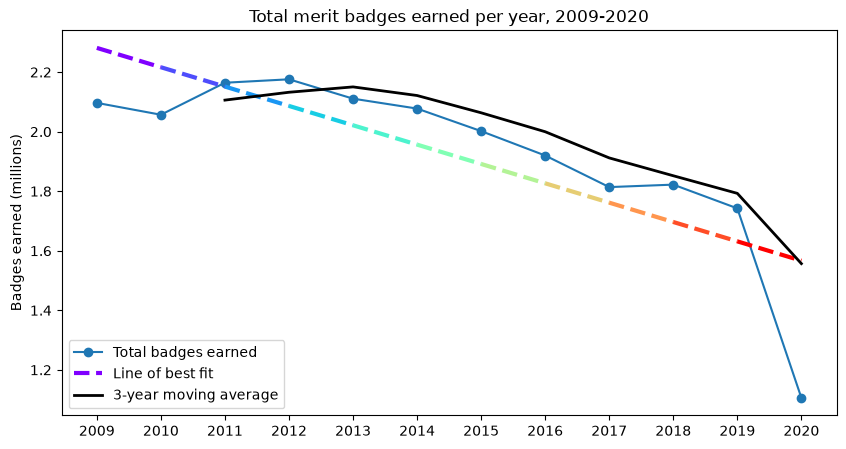

In [72]:

# i went on a side quest im still trying to figure out what happened why did it all go wrong?
# use every year, including 2020
totals = totals_per_year

#remove the 1e6
plt.figure(figsize=(10, 5))
plt.plot(totals.index, totals.values / 1000000, marker="o", label="Total badges earned")

# work out the line of best fit's height at each year
best_fit = np.poly1d(np.polyfit(range(len(totals)), totals.values / 1000000, 1))(range(len(totals)))

#rainbow color line (only the first piece gets a label so the legend shows it once)
for i in range(len(totals) - 1):
    if i == 0:
        plt.plot(totals.index[i:i+2], best_fit[i:i+2], "--", linewidth=3, color=plt.cm.rainbow(i / (len(totals) - 2)), label="Line of best fit")
    else:
        plt.plot(totals.index[i:i+2], best_fit[i:i+2], "--", linewidth=3, color=plt.cm.rainbow(i / (len(totals) - 2)))

# 3-year moving average
plt.plot(totals.index, totals.rolling(3).mean() / 1000000, color="black", linewidth=2, label="3-year moving average")

plt.title("Total merit badges earned per year, 2009-2020")
plt.ylabel("Badges earned (millions)")
plt.legend(loc="lower left")
plt.show()

In [73]:
#i want to see the financial trends of this comapred to this 


In [74]:
#loads a tool for finding files by their name pattern
import glob

# list every IRS form in the folder cuz i have them from 2009-24
pdf_files = sorted(glob.glob("IRS data/*.pdf"))
print(len(pdf_files), "forms")
pdf_files

16 forms


['IRS data/BSA_Form990_2009.pdf',
 'IRS data/BSA_Form990_2010.pdf',
 'IRS data/BSA_Form990_2011.pdf',
 'IRS data/BSA_Form990_2012.pdf',
 'IRS data/BSA_Form990_2013.pdf',
 'IRS data/BSA_Form990_2014.pdf',
 'IRS data/BSA_Form990_2015.pdf',
 'IRS data/BSA_Form990_2016.pdf',
 'IRS data/BSA_Form990_2017.pdf',
 'IRS data/BSA_Form990_2018.pdf',
 'IRS data/BSA_Form990_2019.pdf',
 'IRS data/BSA_Form990_2020.pdf',
 'IRS data/BSA_Form990_2021.pdf',
 'IRS data/BSA_Form990_2022.pdf',
 'IRS data/BSA_Form990_2023.pdf',
 'IRS data/BSA_Form990_2024.pdf']

In [75]:
#my attemp tto solve this wihout manually copying an dpasting this loads Python tool for working with your computers files
import os
os.getcwd()

'/Users/isaac.boruchowicz/hexcoding/Assignment05'

In [76]:
#here i gave up to have code do it and decided to listen to kat and make the files myself and copy and paste 

In [77]:
# the IRS Form 990 summary with revenue expesne asset 
irs = pd.read_csv("IRS data/BSA_990_summary.csv")
irs

,year,total_revenue,total_expenses,net_assets_end
0,2009,209462316,160812795,640154167
1,2010,268858148,237785364,714074666
2,2011,218296402,239504208,677567834
3,2012,191960296,240899881,668475495
4,2013,239799973,273514888,688379899
5,2014,252600778,242975541,702727261
6,2015,236830351,255100241,665165696
7,2016,228928989,273984074,629846235
8,2017,266653263,307700980,633346306
9,2018,285151314,343435152,532523239


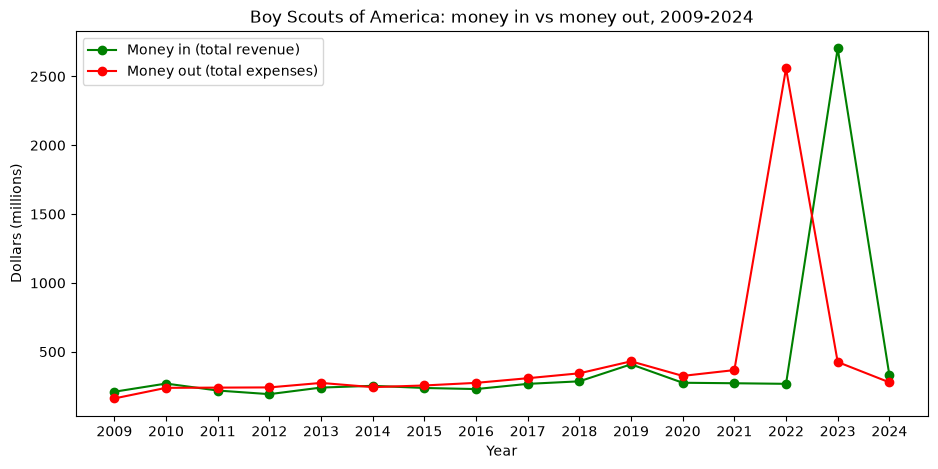

In [78]:
#plotting thisabove
plt.figure(figsize=(11, 5))

# green = money coming in, red = money going out (in millions)
plt.plot(irs["year"], irs["total_revenue"] / 1000000, marker="o", color="green", label="Money in (total revenue)")
plt.plot(irs["year"], irs["total_expenses"] / 1000000, marker="o", color="red", label="Money out (total expenses)")

plt.title("Boy Scouts of America: money in vs money out, 2009-2024")
plt.xlabel("Year")
plt.ylabel("Dollars (millions)")
plt.xticks(irs["year"])
plt.legend()
plt.show()

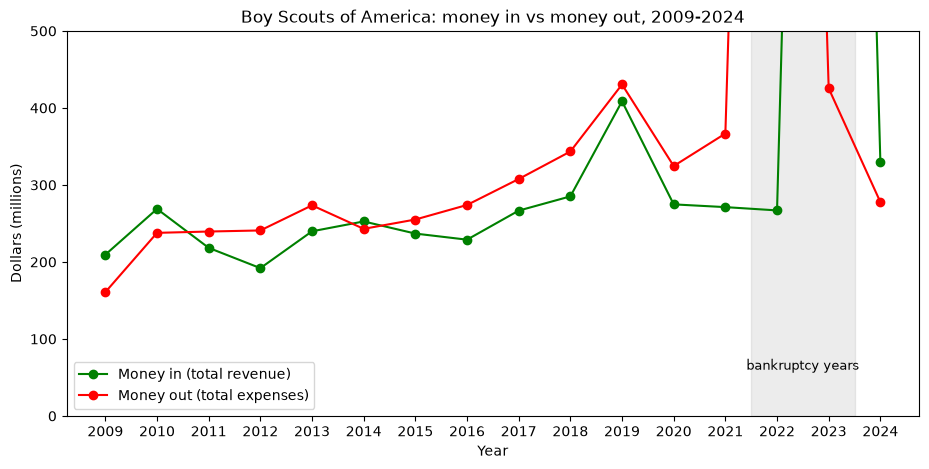

In [79]:
#i need to zoom in 
#that huge jump in money coming in was settlement was paid and the money so it isnt donations or Scouts paying fees Its most likely an accounting entry from settling the bankruptcy so lets ignore for now
plt.figure(figsize=(11, 5))

plt.plot(irs["year"], irs["total_revenue"] / 1000000, marker="o", color="green", label="Money in (total revenue)")
plt.plot(irs["year"], irs["total_expenses"] / 1000000, marker="o", color="red", label="Money out (total expenses)")

# only show up to $500 million so we zoom in so the normal years are visible
plt.ylim(0, 500)

# grey box over the bankruptcy years which go way off the top
plt.axvspan(2021.5, 2023.5, color="gray", alpha=0.15)
plt.text(2022.5, 60, "bankruptcy years", ha="center", fontsize=9)

plt.title("Boy Scouts of America: money in vs money out, 2009-2024")
plt.xlabel("Year")
plt.ylabel("Dollars (millions)")
plt.xticks(irs["year"])
plt.legend(loc="lower left")
plt.show()

In [80]:
#from 2014 they started to loos money  consistently for about 10 years 
#bump in 2018-2019 
#2014 last year they made money 


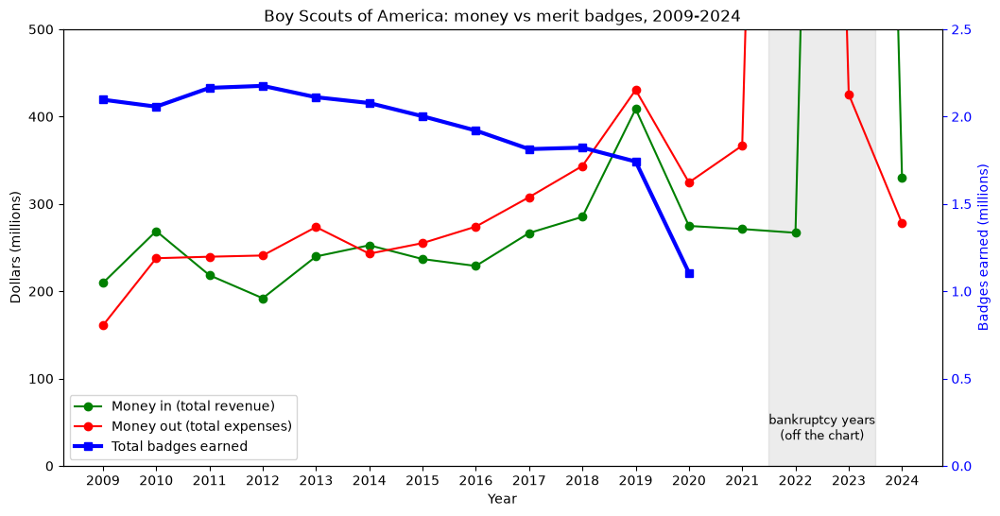

In [81]:
#wnted to plot total badges to this 
fig, money = plt.subplots(figsize=(12, 6))

# money in and money out, using the left axis (millions of dollars)
money.plot(irs["year"], irs["total_revenue"] / 1000000, marker="o", color="green", label="Money in (total revenue)")
money.plot(irs["year"], irs["total_expenses"] / 1000000, marker="o", color="red", label="Money out (total expenses)")
money.set_ylim(0, 500)
money.axvspan(2021.5, 2023.5, color="gray", alpha=0.15)
money.text(2022.5, 30, "bankruptcy years\n(off the chart)", ha="center", fontsize=9)
money.set_ylabel("Dollars (millions)")
money.set_xlabel("Year")
money.set_xticks(irs["year"])

# a second axis on the right side, sharing the same years
badges = money.twinx()

# total badges, using the right axis 
badge_years = totals_per_year.index.astype(int)
badges.plot(badge_years, totals_per_year.values / 1000000, marker="s", color="blue", linewidth=3, label="Total badges earned")
badges.set_ylim(0, 2.5)
badges.set_ylabel("Badges earned (millions)", color="blue")
badges.tick_params(axis="y", colors="blue")

# one legend for all three lines
lines1, labels1 = money.get_legend_handles_labels()
lines2, labels2 = badges.get_legend_handles_labels()
money.legend(lines1 + lines2, labels1 + labels2, loc="lower left")

plt.title("Boy Scouts of America: money vs merit badges, 2009-2024")
plt.show()

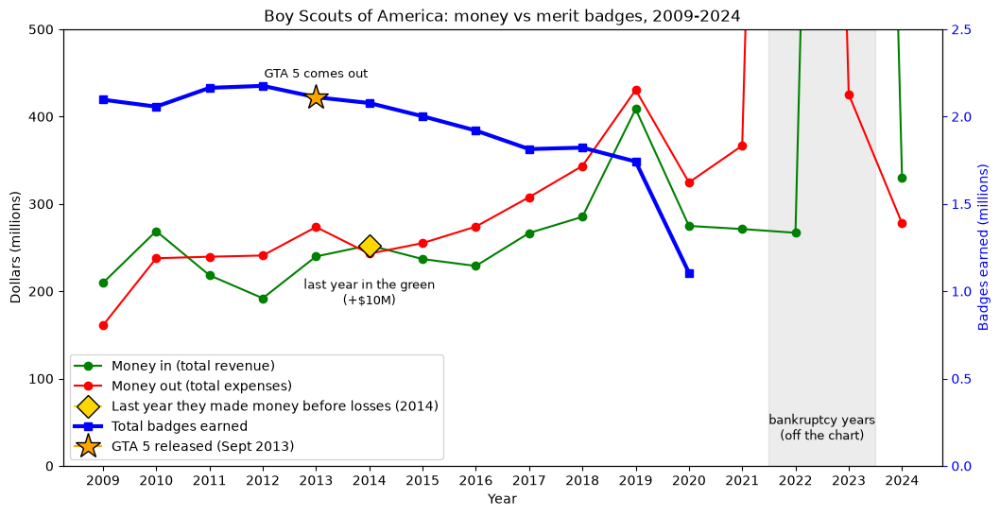

In [82]:
fig, money = plt.subplots(figsize=(12, 6))

# money in and money out, using the left axis (millions of dollars)
money.plot(irs["year"], irs["total_revenue"] / 1000000, marker="o", color="green", label="Money in (total revenue)")
money.plot(irs["year"], irs["total_expenses"] / 1000000, marker="o", color="red", label="Money out (total expenses)")
money.set_ylim(0, 500)
money.axvspan(2021.5, 2023.5, color="gray", alpha=0.15)
money.text(2022.5, 30, "bankruptcy years\n(off the chart)", ha="center", fontsize=9)

#  diamond on 2014 
money_in_2014 = irs.loc[irs["year"] == 2014, "total_revenue"].values[0] / 1000000
money.plot(2014, money_in_2014, marker="D", markersize=12, color="gold", markeredgecolor="black", label="Last year they made money before losses (2014)")
money.annotate("last year in the green\n(+$10M)", xy=(2014, money_in_2014), xytext=(0, -45), textcoords="offset points", ha="center", fontsize=9)

money.set_ylabel("Dollars (millions)")
money.set_xlabel("Year")
money.set_xticks(irs["year"])

# a second axis on the right side, sharing the same years
badges = money.twinx()

# total badges using the right axis
badge_years = totals_per_year.index.astype(int)
badges.plot(badge_years, totals_per_year.values / 1000000, marker="s", color="blue", linewidth=3, label="Total badges earned")
badges.set_ylim(0, 2.5)
badges.set_ylabel("Badges earned (millions)", color="blue")
badges.tick_params(axis="y", colors="blue")

# orange star on the badge line for when GTA 5 came out (Sept 2013)
badges.plot(2013, totals_per_year["2013"] / 1000000, marker="*", markersize=20, color="orange", markeredgecolor="black", label="GTA 5 released (Sept 2013)")
badges.annotate("GTA 5 comes out", xy=(2013, totals_per_year["2013"] / 1000000), xytext=(0, 15), textcoords="offset points", ha="center", fontsize=9)

# one legend for all the lines and markers
lines1, labels1 = money.get_legend_handles_labels()
lines2, labels2 = badges.get_legend_handles_labels()
money.legend(lines1 + lines2, labels1 + labels2, loc="lower left")

plt.title("Boy Scouts of America: money vs merit badges, 2009-2024")
plt.show()

In [83]:
# badges that first showed up in 2013, the year GTA 5 came out
new_badges[new_badges == "2013"]

Merit Badge
Game Design       2013
Programming       2013
Sustainability    2013
dtype: str

In [84]:
# just Game Designs launch numbers
launch_table.loc["Game Design"]

debut year         2013
debut rank        114.0
1 yr later         51.0
2 yrs later        48.0
3 yrs later        41.0
4 yrs later        38.0
best rank          31.0
2025 rank          51.0
jump               63.0
z              1.333956
Name: Game Design, dtype: object

In [85]:
# i had a moment i didnt really know total amount of badges to see ho wimpressive a 51 was just with an eye but ofx with a z score of 1.3 i see its nothign crazy 
print(len(ranks_2009_to_2025))

143


In [86]:
# teen gaming hours per day (ages 15-19) from the BLS American Time Use Survey
gaming = pd.read_csv("IRS data/BLS_teen_gaming_hours_2009_2025.csv")

# badges per year as a table with a number year column so it matches
badges_per_year = totals_per_year.reset_index()
badges_per_year.columns = ["year", "total_badges"]
badges_per_year["year"] = badges_per_year["year"].astype(int)

# only the years that are in both (2009-2019, since gaming has no 2020)
both = pd.merge(badges_per_year, gaming, on="year")
both

,year,total_badges,gaming_hours_per_day_age_15_19
0,2009,2096676.0,0.89
1,2010,2056867.0,0.92
2,2011,2164366.0,1.07
3,2012,2175878.0,0.84
4,2013,2110848.0,0.88
5,2014,2077550.0,0.90
6,2015,2001842.0,1.08
7,2016,1919912.0,0.92
8,2017,1813834.0,1.05
9,2018,1822136.0,1.03


In [87]:
# correlation between badges and gaming hours year by year
r = both["total_badges"].corr(both["gaming_hours_per_day_age_15_19"])
n = len(both)

# turn the correlation into a score beyond 2 or -2 is significant
score = r * (n - 2) ** 0.5 / (1 - r ** 2) ** 0.5

print("correlation:", round(r, 2))

correlation: -0.63


In [88]:
#this is misleading we already know that badges where going down regardless from years prior 
print("score:", round(score, 2))

score: -2.4


In [89]:
# how much each one changed from the year before to stabailize the comparison between somethign already going down and we comapre year to year 
changes = both.set_index("year").diff().dropna()
r2 = changes["total_badges"].corr(changes["gaming_hours_per_day_age_15_19"])
n2 = len(changes)
score2 = r2 * (n2 - 2) ** 0.5 / (1 - r2 ** 2) ** 0.5

print("correlation of changes:", round(r2, 2))
print("score:", round(score2, 2))



correlation of changes: -0.06
score: -0.17


In [90]:
#hypothesis is false GTA DId not infact lead scouts to go bankrupt 

In [91]:
#i then researched if any major org changes happened the years they srated going down. and plotted them 

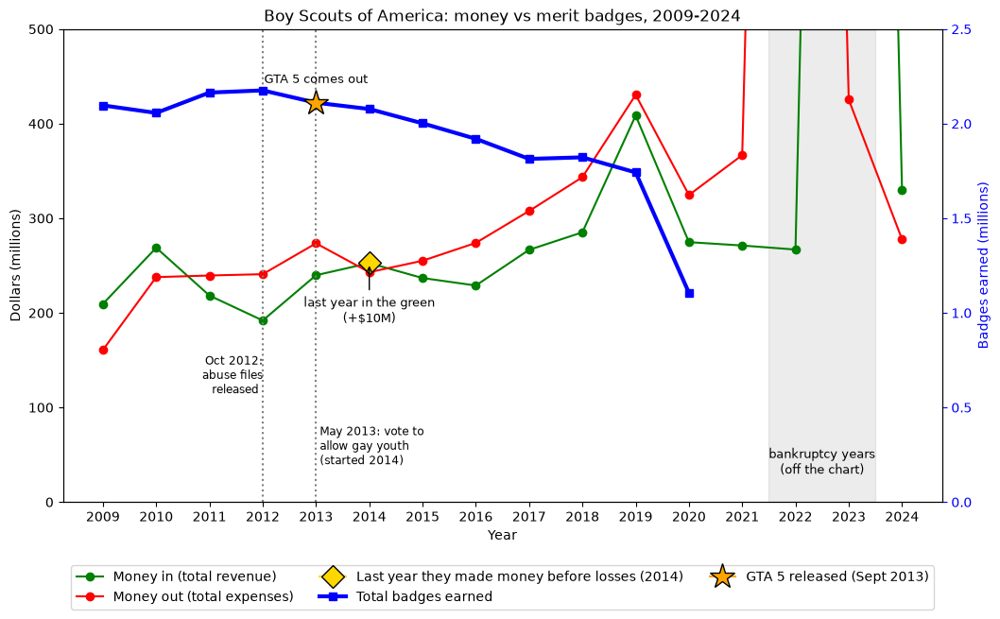

In [92]:
fig, money = plt.subplots(figsize=(12, 6.5))

# money in and money out, using the left axis (millions of dollars)
money.plot(irs["year"], irs["total_revenue"] / 1000000, marker="o", color="green", label="Money in (total revenue)")
money.plot(irs["year"], irs["total_expenses"] / 1000000, marker="o", color="red", label="Money out (total expenses)")
money.set_ylim(0, 500)
money.axvspan(2021.5, 2023.5, color="gray", alpha=0.15)
money.text(2022.5, 30, "bankruptcy years\n(off the chart)", ha="center", fontsize=9)

# gold diamond on 2014: the last year money in was bigger than money out, before the losses started
money_in_2014 = irs.loc[irs["year"] == 2014, "total_revenue"].values[0] / 1000000
money.plot(2014, money_in_2014, marker="D", markersize=12, color="gold", markeredgecolor="black", label="Last year they made money before losses (2014)")
money.annotate("last year in the green\n(+$10M)", xy=(2014, money_in_2014), xytext=(0, -45), textcoords="offset points", ha="center", fontsize=9, arrowprops=dict(arrowstyle="->"))

# dotted lines for the two events
money.axvline(2012, color="gray", linestyle=":")
money.text(2012, 115, "Oct 2012:\nabuse files\nreleased ", fontsize=8.5, ha="right")

money.axvline(2013, color="gray", linestyle=":")
money.text(2013, 40, " May 2013: vote to\n allow gay youth\n (started 2014)", fontsize=8.5)

money.set_ylabel("Dollars (millions)")
money.set_xlabel("Year")
money.set_xticks(irs["year"])

# a second axis on the right side, sharing the same years
badges = money.twinx()

# total badges, using the right axis (millions of badges)
badge_years = totals_per_year.index.astype(int)
badges.plot(badge_years, totals_per_year.values / 1000000, marker="s", color="blue", linewidth=3, label="Total badges earned")
badges.set_ylim(0, 2.5)
badges.set_ylabel("Badges earned (millions)", color="blue")
badges.tick_params(axis="y", colors="blue")

# orange star on the badge line for when GTA 5 came out (Sept 2013
badges.plot(2013, totals_per_year["2013"] / 1000000, marker="*", markersize=20, color="orange", markeredgecolor="black", label="GTA 5 released (Sept 2013)")
badges.annotate("GTA 5 comes out", xy=(2013, totals_per_year["2013"] / 1000000), xytext=(0, 15), textcoords="offset points", ha="center", fontsize=9)

# one legend for everything, under the chart so it doesnt cover the event labels
lines1, labels1 = money.get_legend_handles_labels()
lines2, labels2 = badges.get_legend_handles_labels()
money.legend(lines1 + lines2, labels1 + labels2, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)

plt.title("Boy Scouts of America: money vs merit badges, 2009-2024")
plt.show()

In [93]:
#a couple of things oc abuse files came in thats interesting i looked up and i didnt know this prior there where some heavy bad bad things scout leaders where doing this could explain
#after when gay rights gained much needed momentum during 2013- and onward on their own boy scouts of america voted to allow this (after fighting in 2000 to supreme court to allow a ban
#what followed starts to paint the picture, i then found out most of the boyscout charters or local organizers where from churches and vecause of this a lot of churhes left the scouts meaning a big
#loss in participants 
#I want to see more about the abuse files or more about whats accounted for in the revenue why was so much money goin gout  


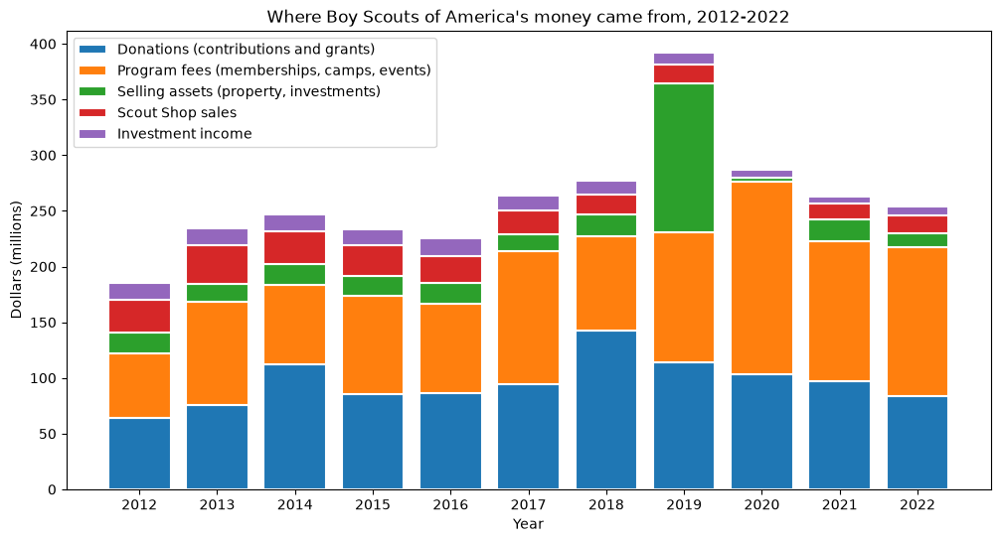

In [94]:
# load all the IRS numbers (one row per year)
irs_all = pd.read_csv("IRS data/BSA_990_all_data.csv")

# keep the years that have the detailed breakdown (2012-2022)
money_in = irs_all.dropna(subset=["contributions_and_grants"]).set_index("year")

# the main places money comes from: label on the chart column in the file
sources = {
    "Donations (contributions and grants)": "contributions_and_grants",
    "Program fees (memberships, camps, events)": "program_service_revenue",
    "Selling assets (property, investments)": "net_gain_from_selling_assets",
    "Scout Shop sales": "net_inventory_sales_scout_shop",
    "Investment income": "investment_income",
}

plt.figure(figsize=(12, 6))

# stack the bars each source sits on top of the ones before it
bottom = pd.Series(0.0, index=money_in.index)
for label, column in sources.items():
    values = money_in[column].clip(lower=0) / 1000000
    plt.bar(money_in.index, values, bottom=bottom, label=label, edgecolor="white", linewidth=1.5)
    bottom = bottom + values

plt.title("Where Boy Scouts of America's money came from, 2012-2022")
plt.ylabel("Dollars (millions)")
plt.xlabel("Year")
plt.xticks(money_in.index)
plt.legend(loc="upper left")
plt.show()

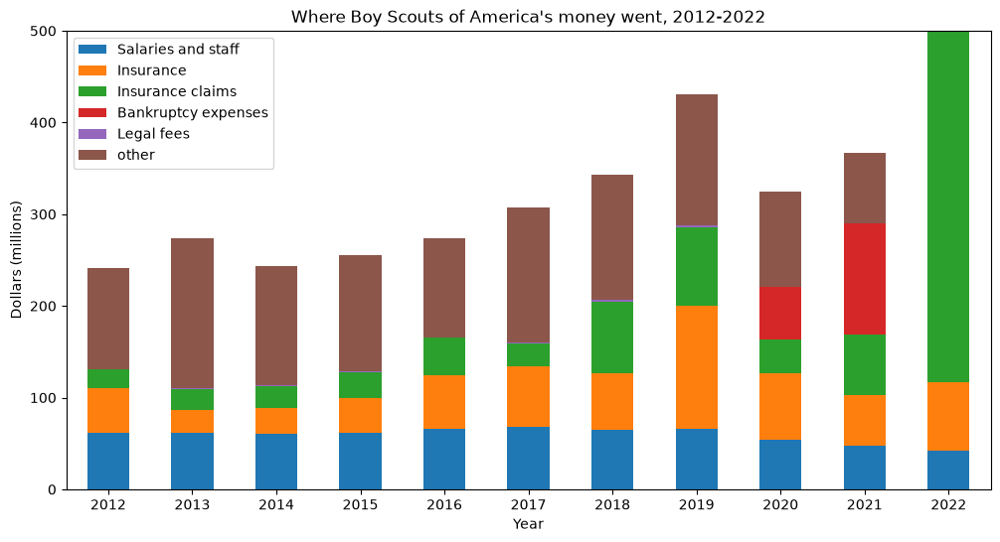

In [95]:
#i wanted to see the expense of bankrupcy and money going out what was coming out of scouting bankrupcy was just in the years it was bankrupt 
# load the two IRS files from the folder
lawsuit = pd.read_csv("IRS data/BSA_990_lawsuit_expenses.csv")
irs_all = pd.read_csv("IRS data/BSA_990_all_data.csv")

#take the 3 salary columns from the second file that has all th einfo plotted
salaries = irs_all[["year", "officer_compensation", "other_salaries_and_wages", "payroll_taxes"]]
money = pd.merge(lawsuit, salaries, on="year")

# keeps the years that have salaries and use years as row labels
money = money[(money["year"] >= 2012) & (money["year"] <= 2022)].set_index("year")

# make a new table one column for each part of the bar
spending = pd.DataFrame()
spending["Salaries and staff"] = money["officer_compensation"] + money["other_salaries_and_wages"] + money["payroll_taxes"]
spending["Insurance"] = money["insurance"]
spending["Insurance claims"] = money["insurance_claims"]
spending["Bankruptcy expenses"] = money["bankruptcy_expenses"]
spending["Legal fees"] = money["legal_fees"]

# other = total spending minus the parts above
spending["other"] = money["total_expenses"] - spending.sum(axis=1)

# turn everything into millions and doesnt blow up the chart 
spending = spending / 1000000

# make it 
spending.plot(kind="bar", stacked=True, figsize=(12, 6), rot=0)
plt.ylim(0, 500)
plt.title("Where Boy Scouts of America's money went, 2012-2022")
plt.ylabel("Dollars (millions)")
plt.xlabel("Year")
plt.show()

In [96]:
#i notice here that insurance after 2014 keeps going up  and insurance claims so i want to dig more 

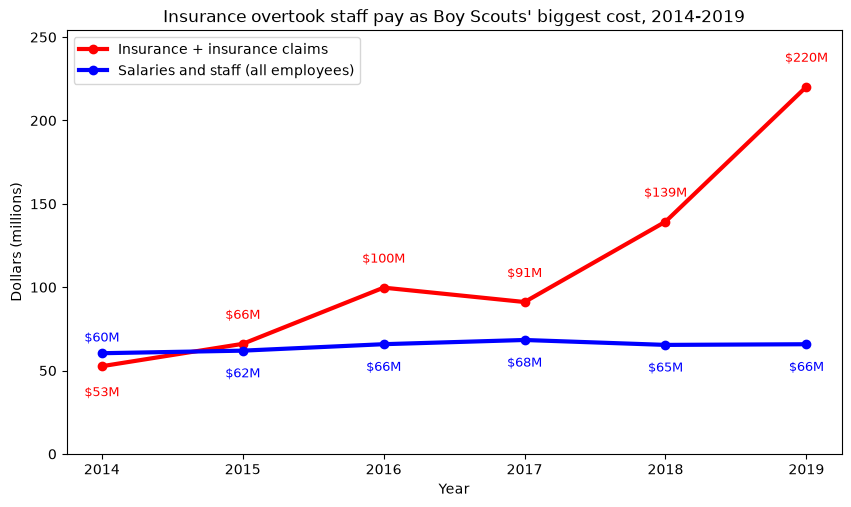

In [97]:
# load both IRS files join them by year keep 2014 2019
irs_all = pd.read_csv("IRS data/BSA_990_all_data.csv")
lawsuit = pd.read_csv("IRS data/BSA_990_lawsuit_expenses.csv")
costs = pd.merge(irs_all, lawsuit.drop(columns="total_expenses"), on="year")
costs = costs[(costs["year"] >= 2014) & (costs["year"] <= 2019)].set_index("year")

# all staff pay together and all insurance together
costs["staff_pay"] = costs["officer_compensation"] + costs["other_salaries_and_wages"] + costs["payroll_taxes"]
costs["insurance_total"] = costs["insurance"] + costs["insurance_claims"]

plt.figure(figsize=(10, 5.5))

# red = insurance
#blue = staff pay
plt.plot(costs.index, costs["insurance_total"] / 1000000, marker="o", color="red", linewidth=3, label="Insurance + insurance claims")
plt.plot(costs.index, costs["staff_pay"] / 1000000, marker="o", color="blue", linewidth=3, label="Salaries and staff (all employees)")

# write the amounts the higher lines label goes above the lower ones below so they don't overlap no matter what happens ? hopefully 
for year in costs.index:
    ins = costs.loc[year, "insurance_total"] / 1000000
    staff = costs.loc[year, "staff_pay"] / 1000000
    plt.text(year, ins + (15 if ins > staff else -18), f"${ins:.0f}M", ha="center", fontsize=9, color="red")
    plt.text(year, staff + (-16 if ins > staff else 7), f"${staff:.0f}M", ha="center", fontsize=9, color="blue")

plt.title("Insurance overtook staff pay as Boy Scouts' biggest cost, 2014-2019")
plt.ylabel("Dollars (millions)")
plt.xlabel("Year")
plt.xticks(costs.index)
plt.ylim(0, 254)
plt.legend(loc="upper left")
plt.show()

In [98]:
#if we go back to the badges they start fallign the moment the lawsuits came out 
#and ofc the moment you start paying, you start showing you where hidding stuff and then parents dont want to send thier kids to this 
#they loose revenue and it all went boom boom 

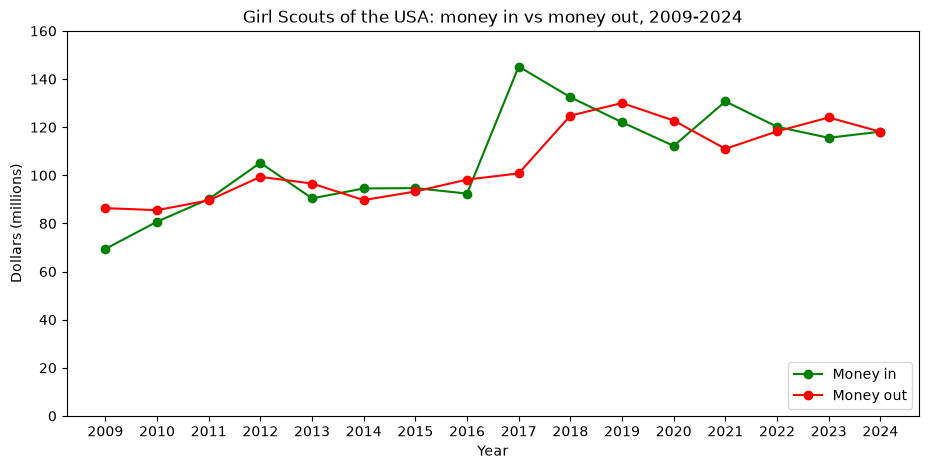

In [99]:
    # Girl Scouts of the USA IRS summary (one row per year, fiscal years ending in September)
girl_scouts = pd.read_csv("Girl Scouts data/GS_990_summary.csv")
#also hand put in i listened to kat 

plt.figure(figsize=(11, 5))
plt.plot(girl_scouts["year"], girl_scouts["total_revenue"] / 1000000, marker="o", color="green", label="Money in")
plt.plot(girl_scouts["year"], girl_scouts["total_expenses"] / 1000000, marker="o", color="red", label="Money out")
plt.title("Girl Scouts of the USA: money in vs money out, 2009-2024")
plt.ylabel("Dollars (millions)")
plt.xlabel("Year")
plt.xticks(girl_scouts["year"])
plt.ylim(0, 160)
plt.legend(loc="lower right")
plt.show()

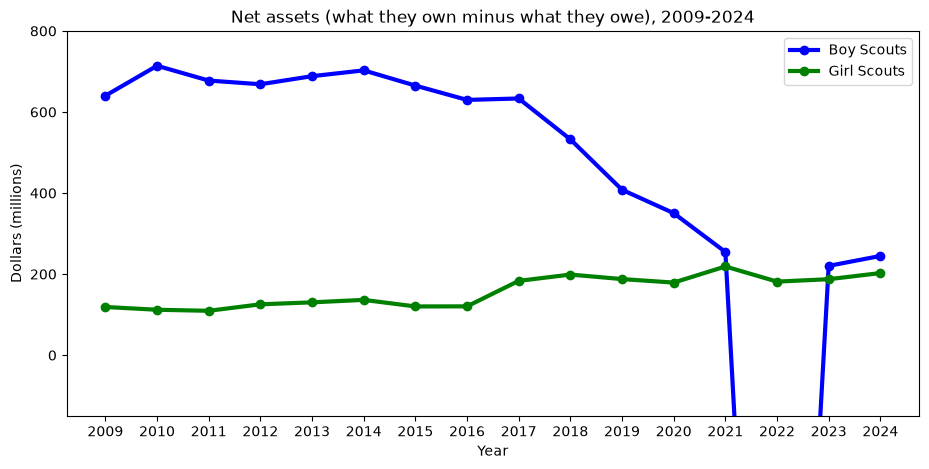

In [100]:
# both organisations net assets on one chart
boy_scouts = pd.read_csv("IRS data/BSA_990_summary.csv")

plt.figure(figsize=(11, 5))
plt.plot(boy_scouts["year"], boy_scouts["net_assets_end"] / 1000000, marker="o", color="blue", linewidth=3, label="Boy Scouts")
plt.plot(girl_scouts["year"], girl_scouts["net_assets_end"] / 1000000, marker="o", color="green", linewidth=3, label="Girl Scouts")

plt.ylim(-150, 800)


plt.title("Net assets (what they own minus what they owe), 2009-2024")
plt.ylabel("Dollars (millions)")
plt.xlabel("Year")
plt.xticks(girl_scouts["year"])
plt.legend(loc="upper right")
plt.show()

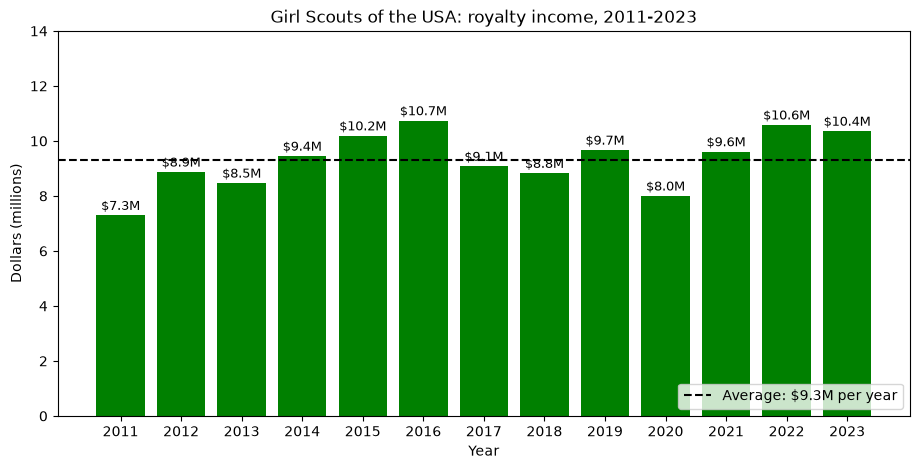

In [101]:
# Girl Scouts royalty income money for letting companies use the Girl Scout name (specifically bakery shops)
royalties = pd.read_csv("Girl Scouts data/GS_royalties.csv")
values = royalties["royalty_income"] / 1000000
average = values.mean()

plt.figure(figsize=(11, 5))

# one bar per year with the amount on top
plt.bar(royalties["year"], values, color="green")
for year, value in zip(royalties["year"], values):
    plt.text(year, value + 0.2, f"${value:.1f}M", ha="center", fontsize=9)

# dashed line at the average
plt.axhline(average, color="black", linestyle="--", label=f"Average: ${average:.1f}M per year")

plt.title("Girl Scouts of the USA: royalty income, 2011-2023")
plt.ylabel("Dollars (millions)")
plt.xlabel("Year")
plt.xticks(royalties["year"])
plt.ylim(0, 14)
plt.legend(loc="lower right")
plt.show()

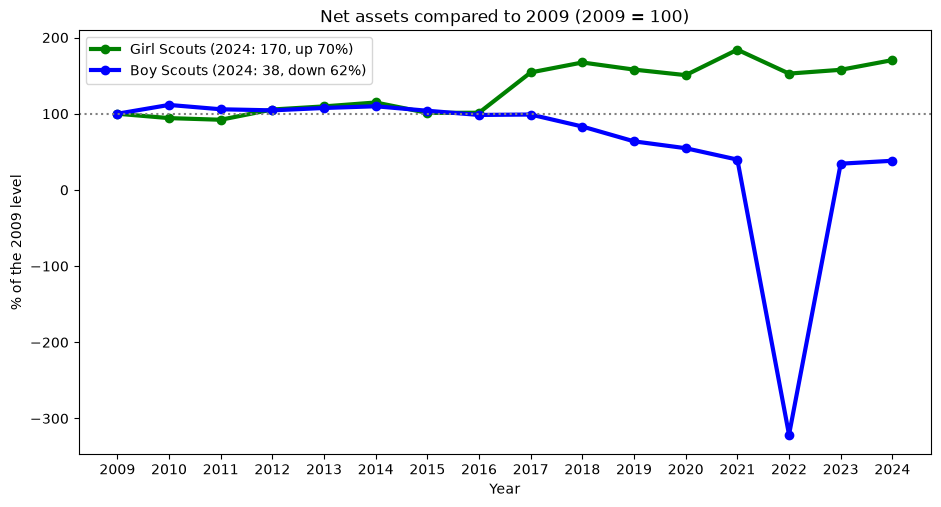

In [102]:
#both org had compelley different starting points some had a lot more assets so i thought what if i stadarize it and comapre each to where i have the datat starting at 2009 and comapre to there the growth

girl_scouts = pd.read_csv("Girl Scouts data/GS_990_summary.csv")
boy_scouts = pd.read_csv("IRS data/BSA_990_summary.csv")

# turn net assets into % of the 2009 level
gs_index = girl_scouts["net_assets_end"] / girl_scouts["net_assets_end"][0] * 100
bsa_index = boy_scouts["net_assets_end"] / boy_scouts["net_assets_end"][0] * 100

plt.figure(figsize=(11, 5.5))

# the 2024 numbers go into the legend so they don't cover the lines
plt.plot(girl_scouts["year"], gs_index, marker="o", color="green", linewidth=3, label=f"Girl Scouts (2024: {gs_index.iloc[-1]:.0f}, up {gs_index.iloc[-1] - 100:.0f}%)")
plt.plot(boy_scouts["year"], bsa_index, marker="o", color="blue", linewidth=3, label=f"Boy Scouts (2024: {bsa_index.iloc[-1]:.0f}, down {100 - bsa_index.iloc[-1]:.0f}%)")

# dotted line at 100 = where they both started in 2009
plt.axhline(100, color="gray", linestyle=":")




plt.title("Net assets compared to 2009 (2009 = 100)")
plt.ylabel("% of the 2009 level")
plt.xlabel("Year")
plt.xticks(girl_scouts["year"])
plt.legend(loc="upper left")
plt.show()

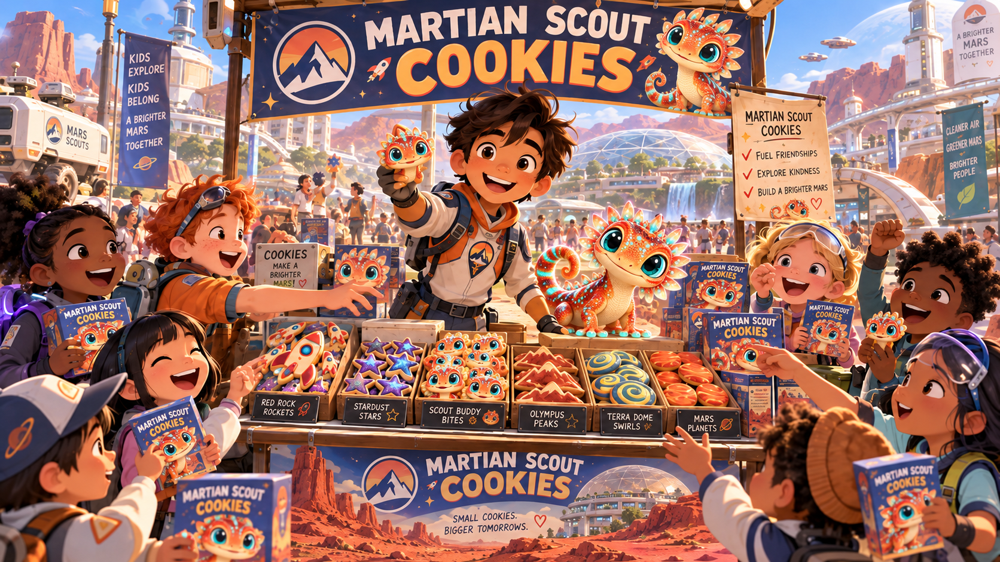

In [103]:
from IPython.display import Image
#CONCLUSION BE MORE LIKE GIRL SCOUTS
# show the picture from the Cookies folder
Image("Cookies/Martian Scout Cookies Festival.png")